# IA101 — Apprentissage machine avec Scikit-learn

## Notebook 0 — Motivation

**Calcul Québec** · Atelier en ligne · Durée de ce notebook : 10 minutes

L'atelier montre comment créer des modèles prédictifs avec scikit-learn et explore les principales méthodes de **classification**, de **prédiction** (régression) et de **détection de structures** dans les données. Il suit le programme annoncé :

1. **Motivation** (ce notebook)
2. **Introduction en douceur aux mathématiques de l'apprentissage machine** (notebook 1)
3. **Exercices et applications pratiques** (notebooks 2 à 6)

### Objectifs de l'atelier

À la fin de l'atelier, les participants seront en mesure de :

| # | Objectif | Partie du programme | Notebooks |
| --- | --- | --- | --- |
| O1 | Situer un problème dans la bonne famille de méthodes : classification, régression ou regroupement | Motivation | 0 |
| O2 | Expliquer le fonctionnement de l'apprentissage : modèle, fonction de perte, gradient, descente de gradient, généralisation | Mathématiques de l'apprentissage machine | 1 |
| O3 | Entraîner un modèle de classification ou de régression avec l'interface `fit` / `predict` / `score` de scikit-learn | Exercices et applications | 2, 6 |
| O4 | Évaluer un modèle avec une métrique adaptée au problème et au coût des erreurs | Exercices et applications | 3 |
| O5 | Améliorer un modèle de façon rigoureuse : prétraitement, validation croisée, recherche d'hyperparamètres | Exercices et applications | 4 |
| O6 | Détecter des structures dans des données non étiquetées : regroupement (k-moyennes) et réduction de dimension (ACP) | Exercices et applications | 5 |

### Prérequis

- Bonnes connaissances en statistiques : fonctions et dérivées.
- Programmation Python (niveau du cours PYT101).
- Analyse et visualisation de données avec NumPy, pandas et Matplotlib (niveau des cours DAT201 et DAT203).

### Déroulement (13 h 30 à 16 h 30)

| Heure | Notebook | Contenu |
| --- | --- | --- |
| 13 h 30 | 0 — Motivation | Programmation classique et apprentissage machine ; familles de problèmes |
| 13 h 40 | 1 — Mathématiques de l'apprentissage | Modèle, perte, gradient, descente de gradient, généralisation |
| 14 h 20 | 2 — Premier modèle de classification | Interface scikit-learn, k plus proches voisins, normalisation |
| 14 h 50 | *Pause* | |
| 15 h 00 | 3 — Évaluer un modèle | Matrice de confusion, précision, rappel, seuil de décision |
| 15 h 20 | 4 — Améliorer un modèle | Sous-apprentissage et surapprentissage, validation croisée, `GridSearchCV` |
| 15 h 50 | 5 — Détecter des structures | k-moyennes, analyse en composantes principales |
| 16 h 05 | 6 — Application intégratrice | Démarche complète sur un problème de régression |
| 16 h 25 | Synthèse | Questions, évaluation de l'atelier |

### Conventions utilisées dans les notebooks

| Mention | Signification |
| --- | --- |
| **Prédiction** | Avant d'exécuter la cellule, formulez votre hypothèse sur le résultat. |
| **Exercice** | Complétez les lignes marquées `# À COMPLÉTER`. Une solution repliable suit chaque exercice. |
| **Question de vérification** | Question à choix multiples avec rétroaction immédiate. |
| **À retenir** | Synthèse du notebook. |

Pour exécuter une cellule : sélectionnez-la, puis appuyez sur **Maj + Entrée**.

### Test de positionnement (2 minutes)

Répondez brièvement, sans recherche, dans la cellule suivante. Le même test est repris à la fin de l'atelier (notebook 6) afin de mesurer la progression.

1. Que « apprend » un modèle pendant l'entraînement ?
2. À quoi sert l'ensemble de test ?
3. Exactitude d'entraînement : 99 %. Exactitude de test : 70 %. Quel est le diagnostic ?
4. Pour un test de dépistage, quelle métrique faut-il surveiller en priorité ?
5. Nommez une pratique qui améliore un modèle et une pratique qui fausse son évaluation.

In [ ]:
# Réponses au début de l'atelier
# 1.
# 2.
# 3.
# 4.
# 5.

In [ ]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Programmation classique et apprentissage machine

En **programmation classique**, le développeur écrit explicitement les règles ; l'ordinateur les applique aux données.

En **apprentissage machine**, on fournit des **exemples** (des données accompagnées des réponses attendues) et un algorithme **estime les règles** à partir de ces exemples. Ces règles prennent la forme des **paramètres** d'un modèle.

### Exemple : reconnaître un fruit

On veut reconnaître une pomme, une orange ou une banane à partir de deux mesures : sa longueur et la texture de sa peau.

| | Programmation classique | Apprentissage machine |
|---|---|---|
| **Ce que l'on fournit** | Les données et les règles | Les données et les réponses attendues |
| **Exemple** | « Plus de 12 cm : banane. Sinon, peau rugueuse : orange. Sinon : pomme. » | 7,5 cm, lisse → `POMME` ; 8 cm, rugueuse → `ORANGE` ; 19 cm, lisse → `BANANE` |
| **Ce que l'on obtient** | Une réponse pour chaque nouveau fruit | Un modèle qui contient des règles estimées |

Dans la cellule suivante, le modèle reçoit uniquement des mesures et des étiquettes. Personne ne lui indique quelles mesures regarder, ni dans quel ordre.

Il retrouve une logique semblable à celle du développeur : il sépare d'abord les bananes selon la longueur, avec un seuil estimé à **13 cm**, puis distingue les pommes des oranges selon la peau. Ces règles viennent des exemples fournis : d'autres exemples donneraient d'autres seuils.

### Quand l'apprentissage machine est-il utile ?

Avec deux mesures propres, un `if/else` suffit, et l'apprentissage machine n'apporte rien. Mais supposons maintenant que l'entrée soit une **photo de fruit** : pour l'ordinateur, ce n'est qu'un tableau de milliers de valeurs de pixels.

- **Règles trop complexes :** aucune suite de `if/else` écrite à la main ne peut couvrir tous les éclairages, les angles, les variétés et les fruits partiellement cachés.
- **Règles difficiles à formuler :** nous reconnaissons une pomme instantanément, sans pouvoir expliquer comment nous le faisons à partir des pixels.
- **Règles qui changent :** si l'on ajoute une nouvelle variété ou un nouveau fruit, on peut réentraîner le modèle avec de nouveaux exemples plutôt que de réécrire le programme.

En revanche, il est facile de rassembler des milliers de photos étiquetées `pomme`, `orange` ou `banane`, et c'est de ces exemples que le modèle apprend.

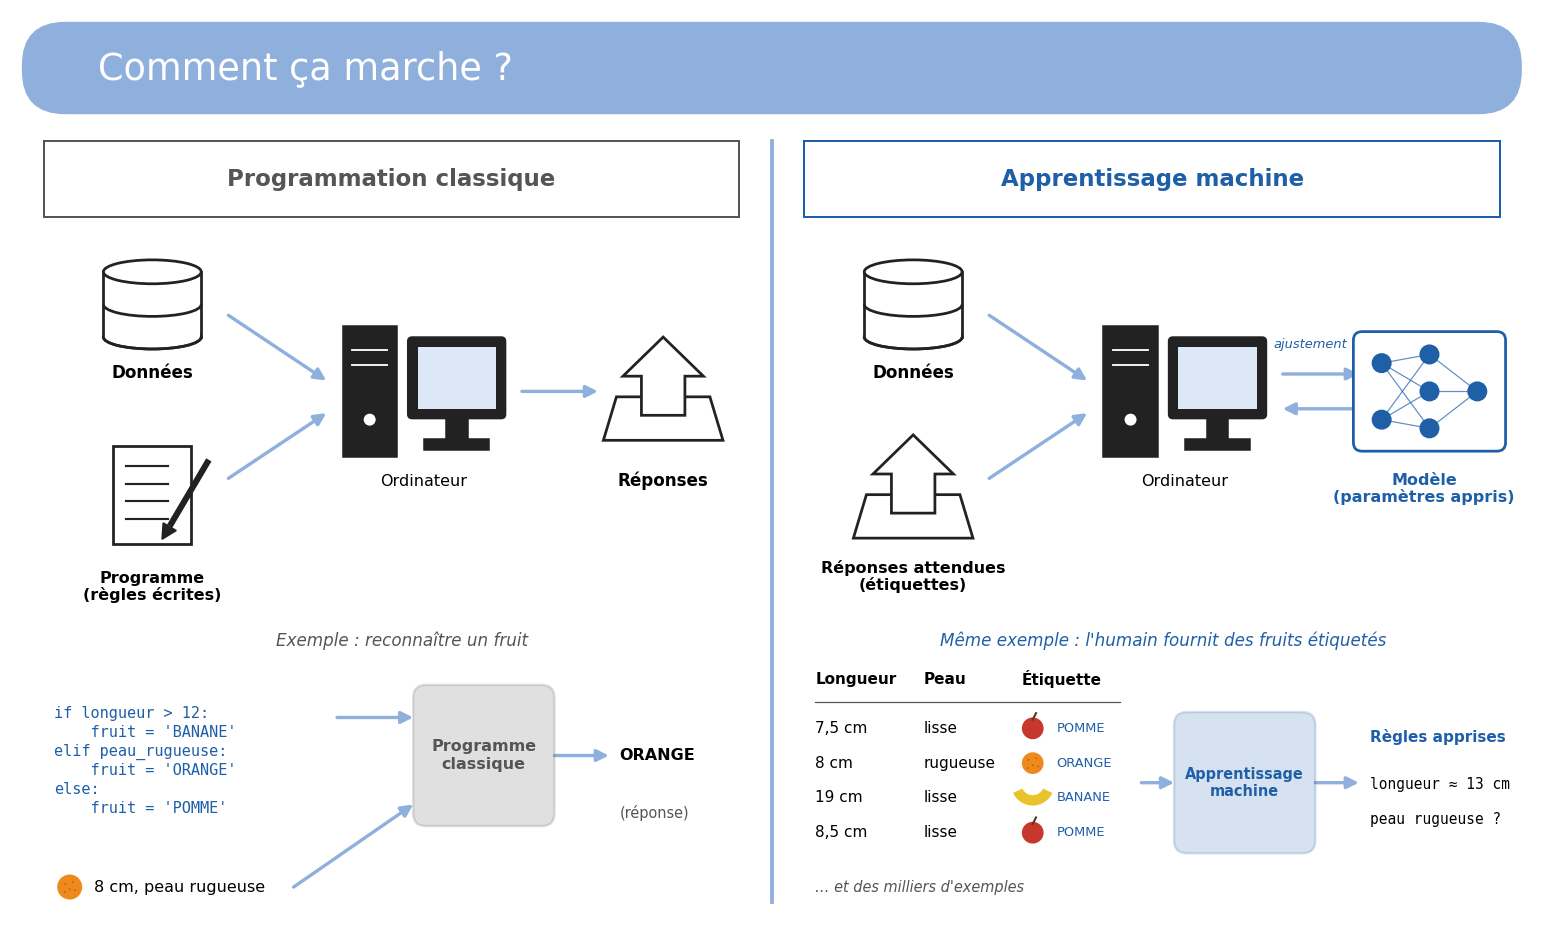

In [ ]:
# @title
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle, Ellipse, FancyArrowPatch, FancyBboxPatch, Polygon, Rectangle, Wedge

GRIS, BLEU, BLEU_CLAIR, ENCRE = "#555555", "#1f5fa8", "#8fb0dd", "#222222"


def fleche(ax, depart, arrivee, couleur=BLEU_CLAIR, lw=2.2, style="-|>"):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle=style, mutation_scale=16,
                                 color=couleur, lw=lw, shrinkA=0, shrinkB=0, zorder=2))


def boite(ax, x, y, l, h, texte, couleur, plein=True, taille=11):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1.2",
                                fc=couleur if plein else "white", ec=couleur, lw=1.6,
                                alpha=0.18 if plein else 1, zorder=3))
    ax.text(x + l / 2, y + h / 2, texte, ha="center", va="center", fontsize=taille,
            fontweight="bold", color=couleur, zorder=4)


def icone_donnees(ax, x, y, c=ENCRE):
    """Base de données : trois disques empilés."""
    l, h, e = 9, 2.2, 3
    ax.add_patch(Rectangle((x - l / 2, y - e), l, 2 * e, fc="white", ec="none", zorder=3))
    ax.plot([x - l / 2, x - l / 2], [y - e, y + e], color=c, lw=1.8, zorder=4)
    ax.plot([x + l / 2, x + l / 2], [y - e, y + e], color=c, lw=1.8, zorder=4)
    ax.add_patch(Ellipse((x, y - e), l, h, fc="white", ec=c, lw=1.8, zorder=3))
    ax.add_patch(Rectangle((x - l / 2 + .1, y - e), l - .2, 2 * e, fc="white", ec="none", zorder=3.5))
    for dy in (-e, 0):
        ax.add_patch(Arc((x, y + dy), l, h, theta1=180, theta2=360,
                                                color=c, lw=1.8, zorder=4))
    ax.add_patch(Ellipse((x, y + e), l, h, fc="white", ec=c, lw=1.8, zorder=4))


def icone_document(ax, x, y, c=ENCRE):
    """Feuille avec des lignes et un crayon."""
    ax.add_patch(Rectangle((x - 3.6, y - 4.5), 7.2, 9, fc="white", ec=c, lw=1.8, zorder=3))
    for dy in (2.6, 1, -.6, -2.2):
        ax.plot([x - 2.4, x + 1.4], [y + dy] * 2, color=c, lw=1.4, zorder=4)
    ax.plot([x + 5.2, x + 1.6], [y + 3.2, y - 2.9], color=c, lw=4, solid_capstyle="butt", zorder=5)
    ax.add_patch(Polygon([(x + .9, y - 4.1), (x + 1, y - 2.6), (x + 2.2, y - 3.3)], fc=c, ec=c, zorder=5))


def icone_ordinateur(ax, x, y, c=ENCRE):
    """Tour et écran."""
    ax.add_patch(Rectangle((x - 7.5, y - 6), 5, 12, fc=c, ec=c, zorder=3))
    for dy in (3.8, 2.4):
        ax.plot([x - 6.6, x - 3.4], [y + dy] * 2, color="white", lw=1.2, zorder=4)
    ax.add_patch(Circle((x - 5, y - 2.6), .55, fc="white", ec="none", zorder=4))
    ax.add_patch(FancyBboxPatch((x - 1.5, y - 2.5), 9, 7.5, boxstyle="round,pad=0,rounding_size=.4",
                                fc=c, ec=c, zorder=3))
    ax.add_patch(Rectangle((x - .6, y - 1.6), 7.2, 5.7, fc="#dce8f7", ec="none", zorder=4))
    ax.add_patch(Rectangle((x + 2, y - 4.6), 2, 2.1, fc=c, ec=c, zorder=3))
    ax.add_patch(Rectangle((x, y - 5.4), 6, 1, fc=c, ec=c, zorder=3))


def icone_sortie(ax, x, y, c=ENCRE):
    """Bac d'où sort une flèche vers le haut."""
    ax.add_patch(Polygon([(x - 5.5, y - 4.5), (x + 5.5, y - 4.5), (x + 4.3, y - .5), (x - 4.3, y - .5)],
                         fc="white", ec=c, lw=1.8, zorder=3))
    ax.add_patch(Polygon([(x - 2, y - 2.2), (x + 2, y - 2.2), (x + 2, y + 1.4), (x + 3.7, y + 1.4),
                          (x, y + 5), (x - 3.7, y + 1.4), (x - 2, y + 1.4)],
                         fc="white", ec=c, lw=1.8, zorder=4))


def icone_modele(ax, x, y, c=BLEU):
    """Petit réseau de neurones dans un cadre."""
    ax.add_patch(FancyBboxPatch((x - 7, y - 5.5), 14, 11, boxstyle="round,pad=0,rounding_size=.8",
                                fc="white", ec=c, lw=1.8, zorder=3))
    couches = [(x - 4.4, [2.6, -2.6]), (x, [3.4, 0, -3.4]), (x + 4.4, [0])]
    for (x1, ys1), (x2, ys2) in zip(couches, couches[1:]):
        for dy1 in ys1:
            for dy2 in ys2:
                ax.plot([x1, x2], [y + dy1, y + dy2], color=c, lw=.8, alpha=.7, zorder=4)
    for xc, ys in couches:
        for dy in ys:
            ax.add_patch(Circle((xc, y + dy), .85, fc=c, ec=c, zorder=5))


def icone_fruit(ax, x, y, nom, r=1.15):
    """Petit dessin de pomme, d'orange ou de banane."""
    if nom == "POMME":
        ax.add_patch(Circle((x, y), r, fc="#c8372d", ec="none", zorder=4))
        ax.plot([x, x + .3], [y + r * .8, y + r * 1.4], color="#5b3a1e", lw=1.4, zorder=5)
    elif nom == "ORANGE":
        ax.add_patch(Circle((x, y), r, fc="#ee8a1d", ec="none", zorder=4))
        for dx, dy in ((-.4, .3), (.3, .45), (0, -.2), (.5, -.3), (-.45, -.45)):
            ax.add_patch(Circle((x + dx, y + dy), .08, fc="#b85f0a", ec="none", zorder=5))
    else:
        ax.add_patch(Wedge((x, y + 1.3), 2, 205, 335, width=.95, fc="#e9c32c", ec="none", zorder=4))


fig, ax = plt.subplots(figsize=(14, 8.4))
ax.set_xlim(0, 140); ax.set_ylim(0, 84); ax.set_aspect("equal"); ax.axis("off")

# Bandeau et titres de colonnes
ax.add_patch(FancyBboxPatch((1, 74.5), 138, 8.5, boxstyle="round,pad=0,rounding_size=4",
                            fc=BLEU_CLAIR, ec="none"))
ax.text(8, 78.7, "Comment ça marche ?", color="white", fontsize=24, va="center")
for x, titre, couleur in ((3, "Programmation classique", GRIS), (73, "Apprentissage machine", BLEU)):
    ax.add_patch(Rectangle((x, 65), 64, 7, fc="white", ec=couleur, lw=1.3))
    ax.text(x + 32, 68.5, titre, ha="center", va="center", fontsize=15, fontweight="bold", color=couleur)
ax.plot([70, 70], [2, 72], color=BLEU_CLAIR, lw=2.5)

# Schéma du haut : programmation classique
icone_donnees(ax, 13, 57); icone_document(ax, 13, 39.5)
ax.text(13, 50.2, "Données", ha="center", fontsize=11, fontweight="bold")
ax.text(13, 32.5, "Programme\n(règles écrites)", ha="center", va="top", fontsize=10.5, fontweight="bold", linespacing=1.1)
fleche(ax, (20, 56), (29, 50)); fleche(ax, (20, 41), (29, 47))
icone_ordinateur(ax, 38, 49)
ax.text(38, 40.3, "Ordinateur", ha="center", fontsize=10.5)
fleche(ax, (47, 49), (54, 49))
icone_sortie(ax, 60, 49)
ax.text(60, 40.3, "Réponses", ha="center", fontsize=11, fontweight="bold")

# Schéma du haut : apprentissage machine
icone_donnees(ax, 83, 57); icone_sortie(ax, 83, 40)
ax.text(83, 50.2, "Données", ha="center", fontsize=11, fontweight="bold")
ax.text(83, 33.5, "Réponses attendues\n(étiquettes)", ha="center", va="top", fontsize=10.5, fontweight="bold", linespacing=1.1)
fleche(ax, (90, 56), (99, 50)); fleche(ax, (90, 41), (99, 47))
icone_ordinateur(ax, 108, 49)
ax.text(108, 40.3, "Ordinateur", ha="center", fontsize=10.5)
fleche(ax, (117, 50.6), (124, 50.6)); fleche(ax, (124, 47.4), (117, 47.4))
icone_modele(ax, 130.5, 49)
ax.text(130, 41.5, "Modèle\n(paramètres appris)", ha="center", va="top", fontsize=10.5, fontweight="bold", color=BLEU, linespacing=1.1)
ax.text(119.5, 53, "ajustement", ha="center", fontsize=8.5, style="italic", color=BLEU)

# Exemple concret
ax.text(36, 25.6, "Exemple : reconnaître un fruit", ha="center", fontsize=11, color=GRIS, style="italic")
ax.text(106, 25.6, "Même exemple : l'humain fournit des fruits étiquetés", ha="center", fontsize=11, color=BLEU, style="italic")

code = ("if longueur > 12:\n"
        "    fruit = 'BANANE'\n"
        "elif peau_rugueuse:\n"
        "    fruit = 'ORANGE'\n"
        "else:\n"
        "    fruit = 'POMME'")
ax.text(4, 15, code, family="monospace", fontsize=10, color=BLEU, va="center", linespacing=1.3)
fleche(ax, (30, 19), (37, 19))
icone_fruit(ax, 5.4, 3.4, "ORANGE")
ax.text(7.6, 3.4, "8 cm, peau rugueuse", fontsize=10.5, va="center")
fleche(ax, (26, 3.4), (37, 11))
boite(ax, 37, 9, 13, 13, "Programme\nclassique", GRIS, taille=10.5)
fleche(ax, (50, 15.5), (55, 15.5))
ax.text(56, 15.5, "ORANGE", fontsize=10.5, fontweight="bold", va="center")
ax.text(56, 10.2, "(réponse)", fontsize=9.5, color=GRIS, va="center")

ax.text(74, 22.5, "Longueur", fontsize=10, fontweight="bold", va="center")
ax.text(84, 22.5, "Peau", fontsize=10, fontweight="bold", va="center")
ax.text(93, 22.5, "Étiquette", fontsize=10, fontweight="bold", va="center")
ax.plot([74, 102], [20.4, 20.4], color=GRIS, lw=.8)
exemples = (("7,5 cm", "lisse", "POMME"), ("8 cm", "rugueuse", "ORANGE"),
            ("19 cm", "lisse", "BANANE"), ("8,5 cm", "lisse", "POMME"))
for i, (longueur, peau, fruit) in enumerate(exemples):
    y = 18 - i * 3.2
    ax.text(74, y, longueur, fontsize=10, va="center"); ax.text(84, y, peau, fontsize=10, va="center")
    icone_fruit(ax, 94, y, fruit, r=1)
    ax.text(96.2, y, fruit, fontsize=8.5, color=BLEU, va="center")
ax.text(74, 3.4, "… et des milliers d'exemples", fontsize=9.5, style="italic", color=GRIS, va="center")
fleche(ax, (104, 13), (107, 13))
boite(ax, 107, 6.5, 13, 13, "Apprentissage\nmachine", BLEU, taille=9.5)
fleche(ax, (120, 13), (124, 13))
ax.text(125, 17.2, "Règles apprises", fontsize=10, fontweight="bold", color=BLEU, va="center")
ax.text(125, 12.8, "longueur ≈ 13 cm", fontsize=9.5, family="monospace", va="center")
ax.text(125, 9.6, "peau rugueuse ?", fontsize=9.5, family="monospace", va="center")

plt.tight_layout(pad=.3)
plt.savefig("programmation_vs_ml.png", dpi=170, bbox_inches="tight", facecolor="white")
plt.show()

### Exercice 1 — Écrire une règle, puis la faire estimer

On dispose de six observations :

| x | 1 | 2 | 3 | 4 | 5 | 6 |
| --- | --- | --- | --- | --- | --- | --- |
| y | 3 | 5 | 7 | 9 | 11 | 13 |

**a)** Écrivez la règle qui relie `x` à `y` (programmation classique).

In [ ]:
def regle_ecrite(x):
    return ...  # À COMPLÉTER

print("Pour x = 10, la règle écrite donne y =", regle_ecrite(10))

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
def regle_ecrite(x):
    return 2 * x + 1

print("Pour x = 10, la règle écrite donne y =", regle_ecrite(10))
```

</details>

**b)** Faites maintenant estimer cette règle par `LinearRegression`, à partir des seuls exemples. Toutes les méthodes de scikit-learn partagent la même interface :

1. **instancier** un estimateur ;
2. l'**entraîner** avec `.fit(X, y)` ;
3. **prédire** avec `.predict(X_nouveau)`.

`X` est toujours une matrice à deux dimensions : une ligne par observation, une colonne par variable.

In [ ]:
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5], [6]])
y = np.array([3, 5, 7, 9, 11, 13])

modele = LinearRegression()
modele.fit(...)                     # À COMPLÉTER
prediction = modele.predict([[10]])

print("Prédiction pour x = 10 :", prediction[0])
print(f"Règle estimée : y = {modele.coef_[0]:.2f} x + {modele.intercept_:.2f}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5], [6]])
y = np.array([3, 5, 7, 9, 11, 13])

modele = LinearRegression()
modele.fit(X, y)
prediction = modele.predict([[10]])

print("Prédiction pour x = 10 :", prediction[0])
print(f"Règle estimée : y = {modele.coef_[0]:.2f} x + {modele.intercept_:.2f}")
```

</details>

L'algorithme retrouve exactement `y = 2x + 1`. Les valeurs 2 et 1 sont les **paramètres** du modèle : ce sont elles qui ont été apprises.

Dans les applications réelles, la relation est **bruitée** et **inconnue**. Exemple : le délai d'arrivée d'une ambulance en fonction de la distance à parcourir dépend aussi de la circulation, de la météo et de l'heure. Aucune droite ne passe par tous les points ; il faut trouver la **meilleure** approximation. C'est l'objet du notebook 1.

In [ ]:
rng = np.random.default_rng(0)
distance = rng.uniform(1, 20, 40)
delai = 1.8 * distance + 4 + rng.normal(0, 3, 40)

plt.figure(figsize=(6, 3.5))
plt.scatter(distance, delai, color="#1f5fa8", alpha=0.8)
plt.xlabel("Distance à parcourir (km)"); plt.ylabel("Délai d'arrivée (min)")
plt.title("Une relation réelle : tendance nette, mais bruitée"); plt.show()

## 2. Les grandes familles de problèmes

| Famille | Question posée | Données d'entraînement | Exemples | Méthodes vues dans l'atelier |
| --- | --- | --- | --- | --- |
| **Classification** (supervisé) | À quelle catégorie appartient cette observation ? | Observations **et** catégories connues | Diagnostic bénin ou malin, type de vin, chiffre manuscrit | k plus proches voisins, régression logistique, arbres, forêts aléatoires |
| **Régression** (supervisé) | Quelle valeur numérique prédire ? | Observations **et** valeurs connues | Délai d'arrivée, progression d'une maladie, consommation énergétique | Régression linéaire, Ridge, forêts aléatoires |
| **Regroupement et réduction de dimension** (non supervisé) | Quelles structures ou tendances existent dans les données ? | Observations **sans** réponse | Segmentation de patients ou de clients, visualisation de données en grande dimension | k-moyennes, analyse en composantes principales |

Dans les méthodes **supervisées**, on connaît la bonne réponse pour les exemples d'entraînement. Dans les méthodes **non supervisées**, on cherche des structures sans réponse de référence.

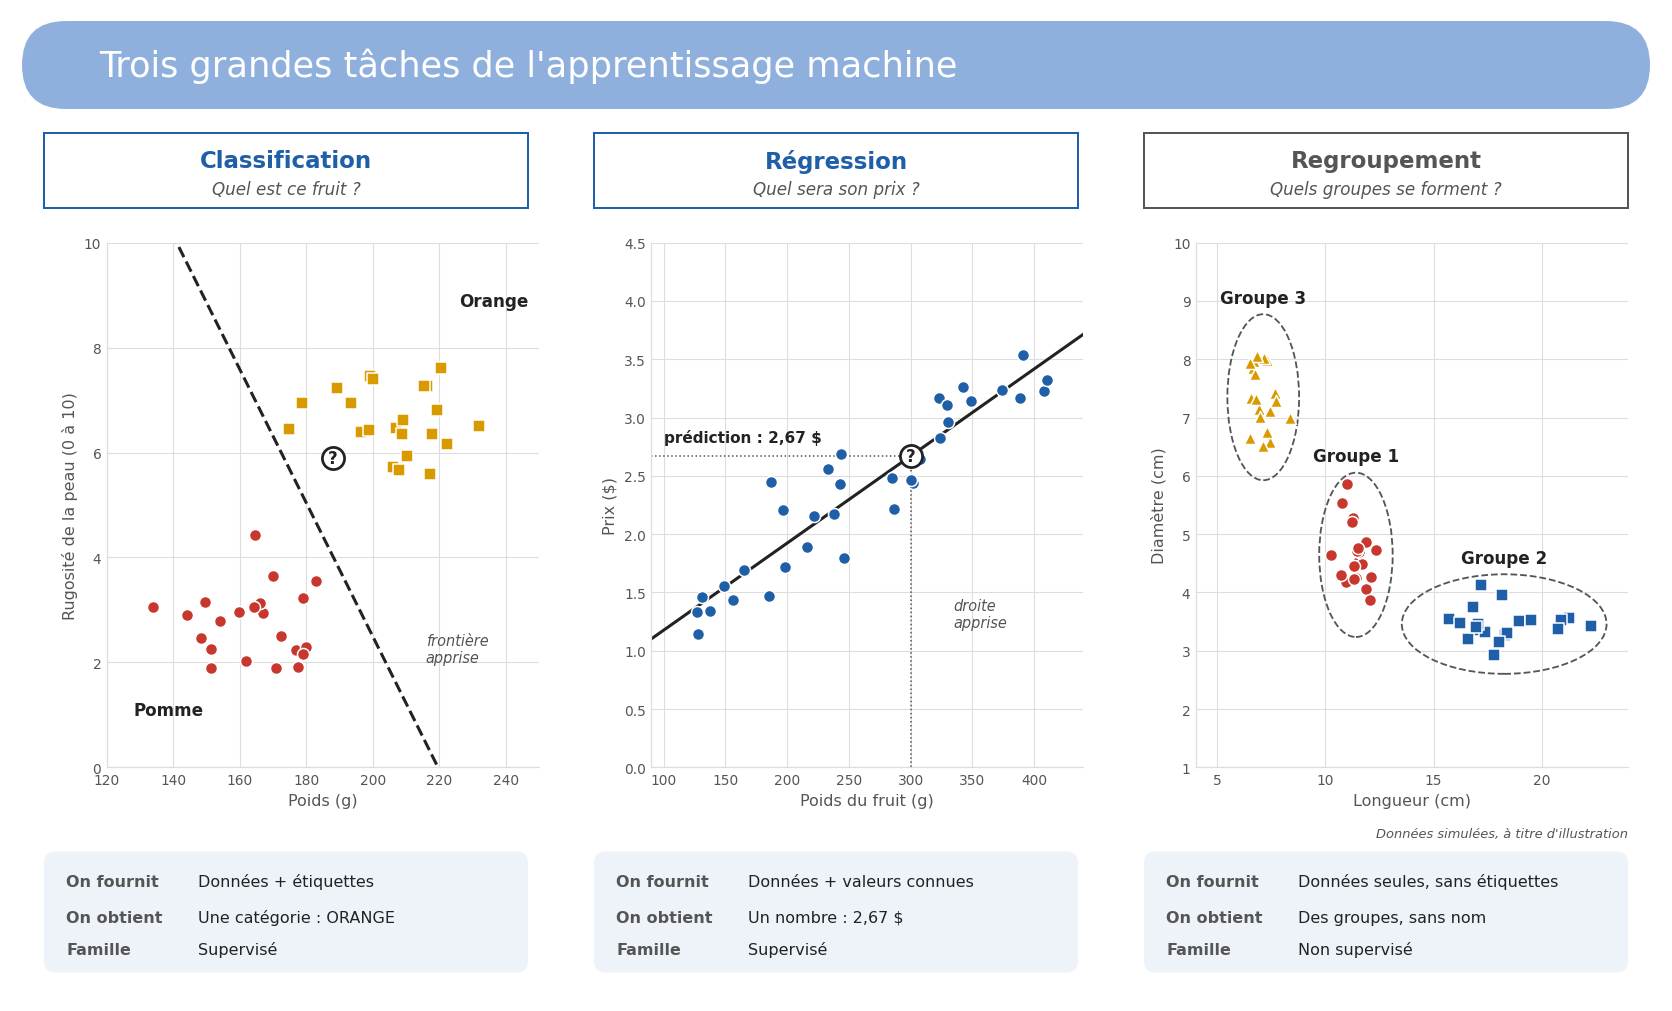

In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse, FancyBboxPatch, Rectangle
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression

ENCRE, GRIS, GRILLE = "#222222", "#555555", "#dddddd"
BLEU, BLEU_CLAIR = "#1f5fa8", "#8fb0dd"
ROUGE, JAUNE = "#c8372d", "#d99a00"
rng = np.random.default_rng(42)


def style_axes(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=10.5, color=GRIS)
    ax.set_ylabel(ylabel, fontsize=10.5, color=GRIS)
    ax.tick_params(colors=GRIS, labelsize=9, length=0)
    ax.grid(color=GRILLE, lw=.7)
    ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)
    for cote in ("left", "bottom"):
        ax.spines[cote].set_color(GRILLE)


def points(ax, x, y, couleur, marqueur, label=None):
    ax.scatter(x, y, s=62, c=couleur, marker=marqueur, edgecolors="white", linewidths=1, label=label, zorder=3)


def nouveau_point(ax, x, y):
    ax.scatter([x], [y], s=210, c="white", edgecolors=ENCRE, linewidths=1.8, zorder=5)
    ax.text(x, y, "?", ha="center", va="center", fontsize=11, fontweight="bold", color=ENCRE, zorder=6)


fig = plt.figure(figsize=(15, 9))
grille = fig.add_gridspec(1, 3, left=.058, right=.98, top=.765, bottom=.235, wspace=.26)
axes = [fig.add_subplot(grille[0, i]) for i in range(3)]

# Fond commun : bandeau, titres et encadrés
fond = fig.add_axes([0, 0, 1, 1], zorder=-1)
fond.set_xlim(0, 150); fond.set_ylim(0, 90); fond.axis("off")
fond.add_patch(FancyBboxPatch((1, 81), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
fond.text(8, 85, "Trois grandes tâches de l'apprentissage machine", color="white", fontsize=23, va="center")

# 1. Classification : frontière estimée entre pommes et oranges
n = 22
pommes = np.column_stack([rng.normal(165, 16, n), rng.normal(2.6, .85, n)])
oranges = np.column_stack([rng.normal(205, 18, n), rng.normal(6.8, .95, n)])
X = np.vstack([pommes, oranges])
y = np.array([0] * n + [1] * n)
clf = LogisticRegression().fit(X, y)

ax = axes[0]
xx = np.array([120.0, 250.0])
yy = -(clf.intercept_[0] + clf.coef_[0, 0] * xx) / clf.coef_[0, 1]
ax.plot(xx, yy, color=ENCRE, lw=2, ls="--", zorder=2)
points(ax, *pommes.T, ROUGE, "o")
points(ax, *oranges.T, JAUNE, "s")
xq, yq = 188.0, 5.9
nouveau_point(ax, xq, yq)
ax.set_xlim(120, 250); ax.set_ylim(0, 10)
ax.text(128, 1, "Pomme", fontsize=11, fontweight="bold", color=ENCRE)
ax.text(226, 8.8, "Orange", fontsize=11, fontweight="bold", color=ENCRE)
ax.text(216, 2.0, "frontière\napprise", fontsize=9.5, style="italic", color=GRIS)
style_axes(ax, "Poids (g)", "Rugosité de la peau (0 à 10)")
categorie = ["POMME", "ORANGE"][clf.predict([[xq, yq]])[0]]

# 2. Régression : droite estimée entre poids et prix
poids = rng.uniform(100, 420, 34)
prix = .35 + .0078 * poids + rng.normal(0, .22, 34)
reg = LinearRegression().fit(poids.reshape(-1, 1), prix)

ax = axes[1]
xx = np.array([90.0, 440.0])
ax.plot(xx, reg.predict(xx.reshape(-1, 1)), color=ENCRE, lw=2, zorder=2)
points(ax, poids, prix, BLEU, "o")
xq2 = 300.0
yq2 = reg.predict([[xq2]])[0]
ax.plot([xq2, xq2], [0, yq2], color=GRIS, lw=1, ls=":", zorder=2)
ax.plot([90, xq2], [yq2, yq2], color=GRIS, lw=1, ls=":", zorder=2)
nouveau_point(ax, xq2, yq2)
ax.set_xlim(90, 440); ax.set_ylim(0, 4.5)
prix_txt = f"{yq2:.2f}".replace(".", ",") + " $"
ax.text(100, yq2 + .12, f"prédiction : {prix_txt}", fontsize=10, fontweight="bold", color=ENCRE)
ax.text(335, 1.2, "droite\napprise", fontsize=9.5, style="italic", color=GRIS)
style_axes(ax, "Poids du fruit (g)", "Prix ($)")

# 3. Regroupement : aucun nom de fruit n'est fourni à l'algorithme
amas = [np.column_stack([rng.normal(mx, sx, 20), rng.normal(my, sy, 20)])
        for mx, sx, my, sy in ((7.2, .55, 7.2, .5), (11.5, .6, 4.6, .5), (18.5, 1.3, 3.4, .35))]
Xc = np.vstack(amas)
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xc)

ax = axes[2]
for k, (c, m) in enumerate(((ROUGE, "o"), (BLEU, "s"), (JAUNE, "^"))):
    groupe = Xc[km.labels_ == k]
    cx, cy = groupe.mean(axis=0)
    ax.add_patch(Ellipse((cx, cy), 4.8 * groupe[:, 0].std() + 1, 4.8 * groupe[:, 1].std() + .45,
                         fc="none", ec=GRIS, lw=1.2, ls="--", zorder=2))
    points(ax, *groupe.T, c, m)
    ax.text(cx, cy + 2.4 * groupe[:, 1].std() + .42, f"Groupe {k + 1}", ha="center",
            fontsize=11, fontweight="bold", color=ENCRE)
ax.set_xlim(4, 24); ax.set_ylim(1, 10); ax.set_xticks(range(5, 25, 5))
style_axes(ax, "Longueur (cm)", "Diamètre (cm)")

# Titres au-dessus et résumés au-dessous de chaque graphique
colonnes = [
    (3, "Classification", "Quel est ce fruit ?", "Données + étiquettes",
     f"Une catégorie : {categorie}", "Supervisé", BLEU),
    (53, "Régression", "Quel sera son prix ?", "Données + valeurs connues",
     f"Un nombre : {prix_txt}", "Supervisé", BLEU),
    (103, "Regroupement", "Quels groupes se forment ?", "Données seules, sans étiquettes",
     "Des groupes, sans nom", "Non supervisé", GRIS),
]
for x, titre, question, entree, sortie, famille, c in colonnes:
    l = 44
    fond.add_patch(Rectangle((x, 72), l, 6.8, fc="white", ec=c, lw=1.3))
    fond.text(x + l / 2, 76.3, titre, ha="center", va="center", fontsize=15, fontweight="bold", color=c)
    fond.text(x + l / 2, 73.7, question, ha="center", va="center", fontsize=11, style="italic", color=GRIS)
    fond.add_patch(FancyBboxPatch((x, 2.5), l, 11, boxstyle="round,pad=0,rounding_size=1", fc="#eef3fa", ec="none"))
    for dy, cle, val in ((10.8, "On fournit", entree), (7.5, "On obtient", sortie), (4.6, "Famille", famille)):
        fond.text(x + 2, dy, cle, fontsize=10.5, fontweight="bold", color=GRIS, va="center")
        fond.text(x + 14, dy, val, fontsize=10.5, color=ENCRE, va="center")

fig.text(.98, .165, "Données simulées, à titre d'illustration", ha="right", fontsize=8.5, color=GRIS, style="italic")
plt.savefig("types_apprentissage.png", dpi=170, facecolor="white")
plt.show()

In [ ]:
quiz("Un hôpital souhaite prévoir le nombre d'appels d'urgence de la semaine prochaine. De quelle famille de problèmes s'agit-il ?",
     ["Classification", "Régression", "Regroupement"],
     1,
     "La cible est une valeur numérique : il s'agit d'un problème de régression (supervisé).")

In [ ]:
quiz("Aux urgences, un hôpital souhaite prédire, à partir des signes vitaux et des symptômes à l'arrivée, si un patient sera hospitalisé ou renvoyé à domicile. De quelle famille de problèmes s'agit-il ?",
     ["Classification", "Régression", "Regroupement"],
     0,
     "La cible est une catégorie parmi deux possibles (hospitalisé ou renvoyé à domicile) : il s'agit d'un problème de classification (supervisé).")

In [ ]:
quiz("On dispose de dossiers de patients sans diagnostic, et l'on cherche des profils similaires. Quelle famille de méthodes convient ?",
     ["Classification", "Régression", "Regroupement (non supervisé)"],
     2,
     "Sans étiquette de référence, on cherche des structures dans les données : c'est un problème non supervisé.")

## À retenir

- **Programmation classique :** règles + données → réponses. **Apprentissage machine :** données + réponses → règles (paramètres du modèle).
- Trois grandes familles : **classification**, **régression** (supervisées) et **regroupement** (non supervisé).
- Interface commune de scikit-learn : instancier → `.fit(X, y)` → `.predict(X_nouveau)`.

**Notebook suivant :** 1 — Introduction aux mathématiques de l'apprentissage machine.